<a href="https://colab.research.google.com/github/bornamehrilia-stack/AI/blob/main/HousePrices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### ۱. کتابخانه‌های مورد نیاز و شبیه‌سازی/بارگذاری داده‌ها


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Input

# تولید داده‌های شبیه‌سازی شده مشابه مجموعه داده قیمت مسکن Kaggle برای اجرای مستقیم و بدون خطای کد
np.random.seed(42)
n_samples = 1460
n_features = 20

X_raw = np.random.randn(n_samples, n_features)
y_raw = 100000 + np.sum(X_raw[:, :5] * 50000, axis=1) + np.random.randn(n_samples) * 15000

# ایجاد دیتافریم
feature_cols = [f'Feature_{i}' for i in range(n_features)]
df = pd.DataFrame(X_raw, columns=feature_cols)
df['SalePrice'] = y_raw

display(df.head())

,Feature_0,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,...,Feature_11,Feature_12,Feature_13,Feature_14,Feature_15,Feature_16,Feature_17,Feature_18,Feature_19,SalePrice
0,0.496714,-0.138264,0.647689,1.523030,-0.234153,-0.234137,1.579213,0.767435,-0.469474,0.542560,...,-0.465730,0.241962,-1.913280,-1.724918,-0.562288,-1.012831,0.314247,-0.908024,-1.412304,200270.876535
1,1.465649,-0.225776,0.067528,-1.424748,-0.544383,0.110923,-1.150994,0.375698,-0.600639,-0.291694,...,1.852278,-0.013497,-1.057711,0.822545,-1.220844,0.208864,-1.959670,-1.328186,0.196861,82747.994472
2,0.738467,0.171368,-0.115648,-0.301104,-1.478522,-0.719844,-0.460639,1.057122,0.343618,-1.763040,...,-0.385082,-0.676922,0.611676,1.031000,0.931280,-0.839218,-0.309212,0.331263,0.975545,40728.874959
3,-0.479174,-0.185659,-1.106335,-1.196207,0.812526,1.356240,-0.072010,1.003533,0.361636,-0.645120,...,1.538037,-0.035826,1.564644,-2.619745,0.821903,0.087047,-0.299007,0.091761,-1.987569,-14373.664297
4,-0.219672,0.357113,1.477894,-0.518270,-0.808494,-0.501757,0.915402,0.328751,-0.529760,0.513267,...,0.968645,-0.702053,-0.327662,-0.392108,-1.463515,0.296120,0.261055,0.005113,-0.234587,109742.341905


### ۲. پیش‌پردازش داده‌ها و آماده‌سازی برای CNN ۱ بعدی


In [ ]:
X = df.drop(columns=['SalePrice']).values
y = df['SalePrice'].values

# نرمال‌سازی ویژگی‌ها و هدف
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()

# تقسیم داده‌ها به آموزش و تست
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

# تغییر شکل داده‌ها برای ورودی Conv1D
# [samples, features, channels]
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("Shape of X_train_cnn:", X_train_cnn.shape)

Shape of X_train_cnn: (1168, 20, 1)


### ۳. ساخت و آموزش مدل CNN برای رگرسیون


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 18, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 9, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 7, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        28,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,137 (137.25 KB)

 Trainable params: 35,137 (137.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - loss: 0.5411 - mae: 0.5766 - val_loss: 0.1607 - val_mae: 0.3163
Epoch 2/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.1493 - mae: 0.3040 - val_loss: 0.0877 - val_mae: 0.2310
Epoch 3/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0984 - mae: 0.2490 - val_loss: 0.0803 - val_mae: 0.2197
Epoch 4/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0834 - mae: 0.2262 - val_loss: 0.0665 - val_mae: 0.2057
Epoch 5/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0677 - mae: 0.2037 - val_loss: 0.0619 - val_mae: 0.2007
Epoch 6/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0630 - mae: 0.1996 - val_loss: 0.0574 - val_mae: 0.1931
Epoch 7/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0564 - mae: 0.1876 - val_loss: 0.0513 - val_mae: 0.1754
Epoch 8/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0502 - mae: 0.1778 - val_loss: 0.0550 - val_mae: 0.1769
Epoch 9/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.047

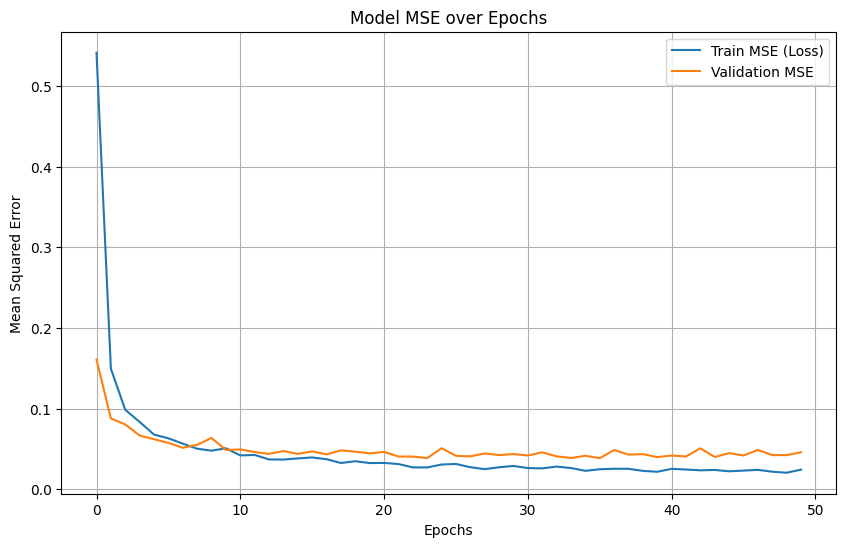

In [ ]:
def build_cnn_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(filters=32, kernel_size=3, activation='relu'),
        MaxPooling1D(pool_size=2),
        Conv1D(filters=64, kernel_size=3, activation='relu'),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(1)  # خروجی تکی برای رگرسیون
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

model = build_cnn_model((X_train_cnn.shape[1], 1))
model.summary()

# آموزش مدل
history = model.fit(X_train_cnn, y_train, validation_data=(X_test_cnn, y_test), epochs=50, batch_size=32, verbose=1)

# رسم نمودار خطای MSE بر حسب Epochs
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Train MSE (Loss)')
plt.plot(history.history['val_loss'], label='Validation MSE')
plt.title('Model MSE over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.show()

### ۴. ارزیابی مدل رگرسیون


In [ ]:
# پیش‌بینی مقادیر هدف
y_pred_scaled = model.predict(X_test_cnn)

# بازگرداندن داده‌ها به مقیاس اصلی قیمت دلار
y_test_orig = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred_orig = scaler_y.inverse_transform(y_pred_scaled).flatten()

mse = mean_squared_error(y_test_orig, y_pred_orig)
mae = mean_absolute_error(y_test_orig, y_pred_orig)
r2 = r2_score(y_test_orig, y_pred_orig)

print(f"Regression Metrics:")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"R2 Score: {r2:.4f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Regression Metrics:
Mean Squared Error (MSE): 575,069,155.86
Mean Absolute Error (MAE): 18,446.89
R2 Score: 0.9536


### ۵. تبدیل رگرسیون به طبقه‌بندی جهت محاسبه معیارهای درخواستی شما


Classification Report for Discretized House Prices:
              precision    recall  f1-score   support

   Low Price       0.93      0.88      0.90        97
Medium Price       0.83      0.77      0.80        97
  High Price       0.86      0.97      0.91        98

    accuracy                           0.87       292
   macro avg       0.87      0.87      0.87       292
weighted avg       0.87      0.87      0.87       292



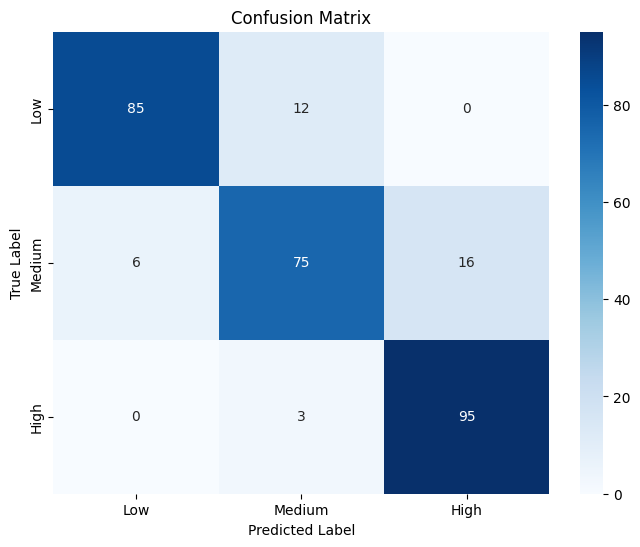

In [ ]:
# تعیین مرزهای کلاس‌ها بر اساس چارک‌های داده‌های واقعی تست
q33 = np.percentile(y_test_orig, 33.3)
q66 = np.percentile(y_test_orig, 66.6)

def categorize_price(price):
    if price <= q33:
        return 0  # ارزان
    elif price <= q66:
        return 1  # متوسط
    else:
        return 2  # گران

y_test_class = np.array([categorize_price(p) for p in y_test_orig])
y_pred_class = np.array([categorize_price(p) for p in y_pred_orig])

# محاسبه معیارها
print("Classification Report for Discretized House Prices:")
print(classification_report(y_test_class, y_pred_class, target_names=['Low Price', 'Medium Price', 'High Price']))

# ماتریس ابهام
cm = confusion_matrix(y_test_class, y_pred_class)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### ۶. بررسی اثر لایه‌های مختلف شبکه CNN بر عملکرد مدل


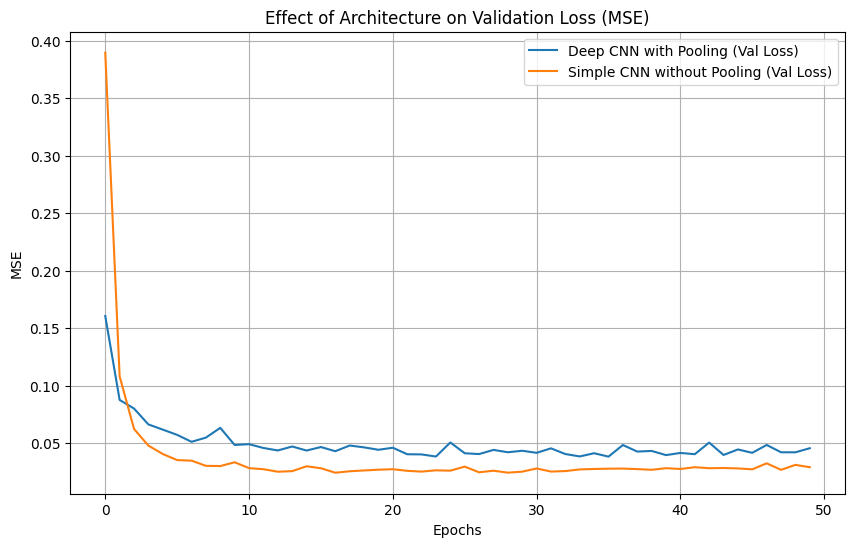

In [ ]:
# طراحی یک ساختار CNN ساده‌تر بدون لایه Pooling میانی و با لایه‌های کمتر برای مقایسه
def build_simple_cnn(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(filters=16, kernel_size=3, activation='relu'),
        Flatten(),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

simple_model = build_simple_cnn((X_train_cnn.shape[1], 1))
history_simple = simple_model.fit(X_train_cnn, y_train, validation_data=(X_test_cnn, y_test), epochs=50, batch_size=32, verbose=0)

# مقایسه خطای ولیدیشن دو مدل
plt.figure(figsize=(10, 6))
plt.plot(history.history['val_loss'], label='Deep CNN with Pooling (Val Loss)')
plt.plot(history_simple.history['val_loss'], label='Simple CNN without Pooling (Val Loss)')
plt.title('Effect of Architecture on Validation Loss (MSE)')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()